# 3.1 Vizualizarea datelor

Generarea unei serii variate de grafice pentru determinarea calitatii, intelegerea si utilizarea datelor in raport cu cerinta.

In [ ]:
%pip install -r ../requirements.txt

In [1]:
# Import necessary libraries

import gc
import sys
import mne
import dask
import numpy as np
import pandas as pd
import seaborn as sns
import warnings as wn
import dask.dataframe as dd
import matplotlib.pyplot as plt

from pathlib import Path

In [2]:
# Ignore all warnings
wn.filterwarnings("ignore")

In [3]:
# Import configuration module

if str(Path.cwd().parent) not in sys.path:
    sys.path.insert(0, str(Path.cwd().parent))

import config as cfg
cfg.ensure_directories()

In [4]:
# Create simple settings and folders

FLATLINE_THRESHOLD = 1e-8
EXTREME_VAR_MULTIPLIER = 5.0
LOW_VAR_MULTIPLIER = 0.1
SEED = cfg.RANDOM_SEED

rng = np.random.default_rng(SEED)
FIG_DIR = cfg.FIGURES_DIR / "eda"
FIG_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")

print("Folder grafice:", cfg.to_relative_path(FIG_DIR))

Folder grafice: reports/figures/eda


In [5]:
# Create a single lazy dataframe from all files

parquet_files = cfg.get_all_parquet_files()
data = dd.read_parquet(parquet_files, engine=cfg.PARQUET_ENGINE).rename(columns=cfg.CHANNEL_MAP)

In [6]:
# Create the pandas dataframes 

trials_df = data[data['timestamp'] == 0][['subject', 'trial', 'label']].compute()
class_df = trials_df.groupby(['subject', 'label']).size().reset_index(name='n_trials')
class_df = class_df.rename(columns={"subject": "subject_id"})

In [7]:
# Subject sub frame

subjects = sorted(trials_df["subject"].unique().tolist())

In [36]:
# Calculate the mean and the std deviation

mean_df = data.groupby('subject')[cfg.MED_COLUMNS].mean().compute()
std_df = data.groupby('subject')[cfg.MED_COLUMNS].std().compute()

In [37]:
# Calculate the minimum and the maximum 

min_df = data.groupby('subject')[cfg.MED_COLUMNS].min().compute()
max_df = data.groupby('subject')[cfg.MED_COLUMNS].max().compute()

In [9]:
# DEfine a function for each electrode region

def get_region(ch_name):
    if ch_name in cfg.ECG_CHANNELS or ch_name in cfg.EOG_CHANNELS:
        return "Aux"
    if ch_name.startswith(("Fp", "AF", "F")) and not ch_name.startswith(("FC", "FT")):
        return "Frontal"
    if ch_name.startswith(("FC", "FT", "C", "T")) and not ch_name.startswith(("CP", "TP")):            
        return "Central/Motor"
    if ch_name.startswith(("CP", "TP", "P")):
        return "Parietal" 
    return "Occipital"

In [38]:
# Calculate each channel dataframe

channel_df = std_df.reset_index().melt(id_vars="subject", var_name="channel", value_name="std")
channel_df["mean"] = mean_df.reset_index().melt(id_vars="subject", var_name="channel", value_name="mean")["mean"]
channel_df = channel_df.rename(columns={"subject": "subject_id"}) 
channel_df["type"] = channel_df["channel"].map(cfg.CHANNEL_TYPES)
channel_df["region"] = channel_df["channel"].map(get_region)
channel_df["range"] = (
    max_df.reset_index().melt(id_vars="subject", var_name="channel", value_name="max")["max"] - min_df.reset_index().melt(id_vars="subject", var_name="channel", value_name="min")["min"]        
)

In [15]:
# Signal processing structures

t_idx = int(rng.integers(0, 600))
one_trial = data[(data["subject"] == 1) & (data["trial"] == t_idx)].compute().sort_values("timestamp")    

sample_trials = rng.choice(600, size=30, replace=False).tolist()
sub1_sample = data[(data["subject"] == 1) & (data["trial"].isin(sample_trials))].compute()

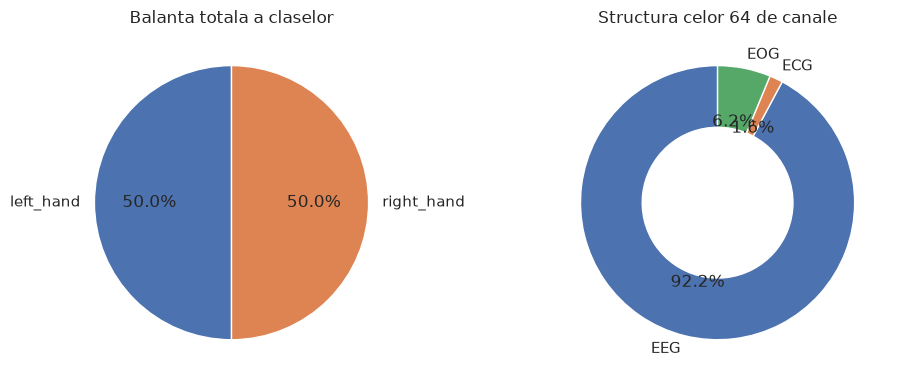

In [12]:
# Pie and Donut charts for overall class balance and channel types

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

label_totals = class_df.groupby("label")["n_trials"].sum()
axes[0].pie(label_totals.values, labels=label_totals.index, autopct="%1.1f%%", startangle=90, colors=["#4C72B0", "#DD8452"])
axes[0].set_title("Balanta totala a claselor")

ch_counts = cfg.get_channel_type_counts()
mod_names = ["EEG", "ECG", "EOG"]
mod_vals = [ch_counts["eeg"], ch_counts["ecg"], ch_counts["eog"]]
axes[1].pie(mod_vals, labels=mod_names, autopct="%1.1f%%", startangle=90, wedgeprops={"width": 0.45})
axes[1].set_title("Structura celor 64 de canale")

plt.tight_layout()
plt.savefig(FIG_DIR / "01_overview_pies.png", dpi=150)
plt.show()
plt.close()

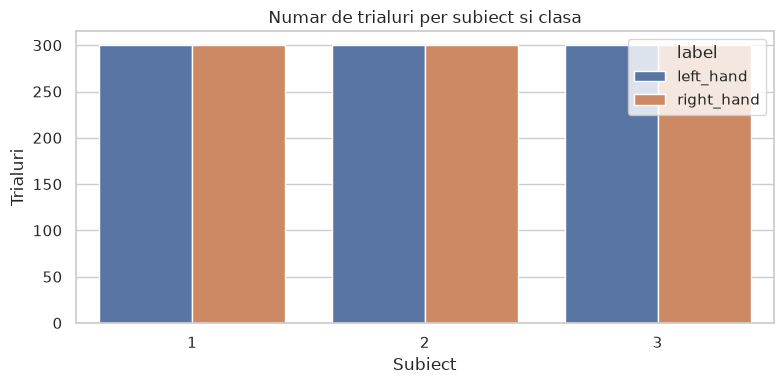

In [13]:
# Grouped bar chart of trial counts per subject and class

sub_cls = class_df.groupby(["subject_id", "label"])["n_trials"].sum().reset_index()

plt.figure(figsize=(8, 4))
sns.barplot(data=sub_cls, x="subject_id", y="n_trials", hue="label")
plt.title("Numar de trialuri per subiect si clasa")
plt.xlabel("Subiect")
plt.ylabel("Trialuri")
plt.tight_layout()
plt.savefig(FIG_DIR / "02_class_counts_per_subject.png", dpi=150)
plt.show()
plt.close()

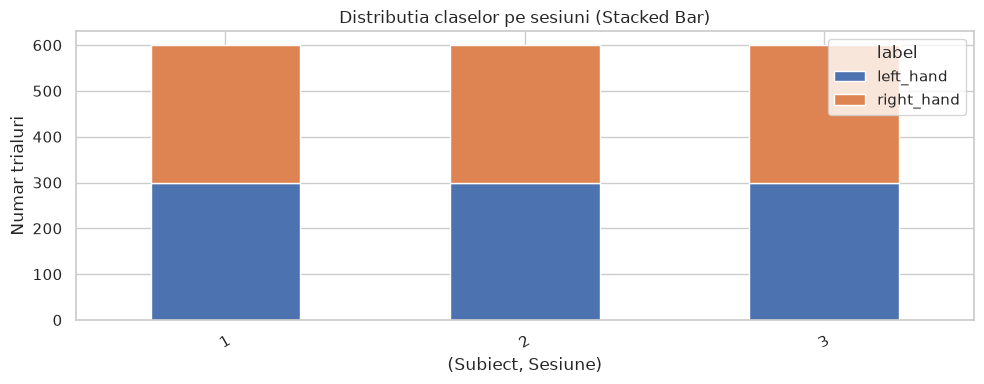

In [16]:
# Stacked bar chart of classes across subjects and sessions

piv = class_df.pivot_table(index="subject_id", columns="label", values="n_trials", fill_value=0)
ax = piv.plot(kind="bar", stacked=True, figsize=(10, 4), color=["#4C72B0", "#DD8452"])
ax.set_title("Distributia claselor pe sesiuni (Stacked Bar)")
ax.set_xlabel("(Subiect, Sesiune)")
ax.set_ylabel("Numar trialuri")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig(FIG_DIR / "03_sessions_stacked_bar.png", dpi=150)
plt.show()
plt.close()

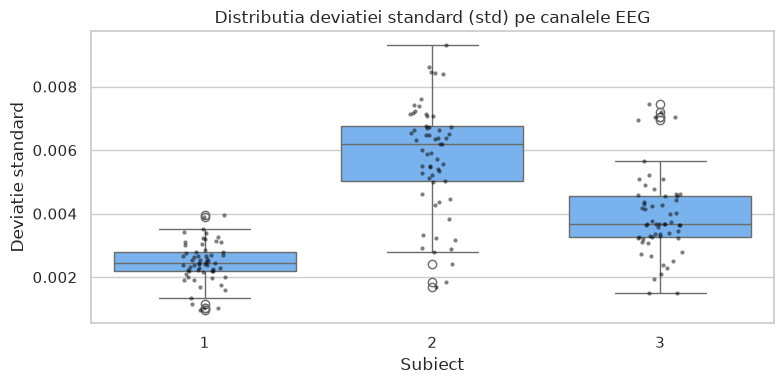

In [17]:
# Box plot of EEG channel standard deviation per subject

eeg_only = channel_df[channel_df["type"] == "eeg"]

plt.figure(figsize=(8, 4))
sns.boxplot(data=eeg_only, x="subject_id", y="std", color="#66B2FF")
sns.stripplot(data=eeg_only, x="subject_id", y="std", color="black", size=3, alpha=0.5)
plt.title("Distributia deviatiei standard (std) pe canalele EEG")
plt.xlabel("Subiect")
plt.ylabel("Deviatie standard")
plt.tight_layout()
plt.savefig(FIG_DIR / "05_eeg_std_boxplot.png", dpi=150)
plt.show()
plt.close()

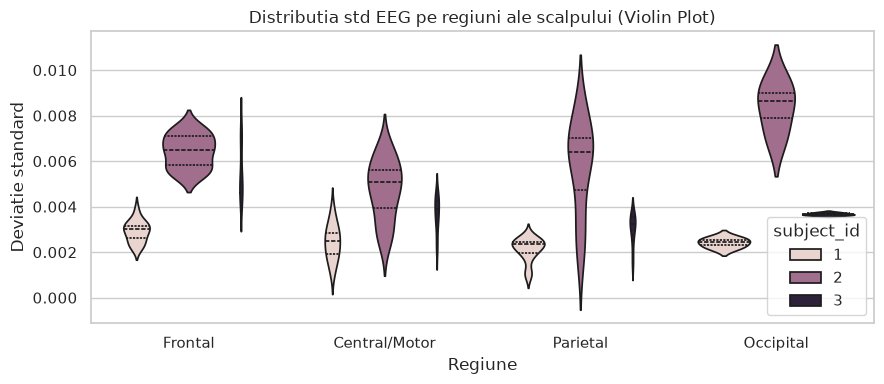

In [18]:
# Violin plot of EEG std across scalp regions

plt.figure(figsize=(9, 4))
sns.violinplot(data=eeg_only, x="region", y="std", hue="subject_id", inner="quartile")
plt.title("Distributia std EEG pe regiuni ale scalpului (Violin Plot)")
plt.xlabel("Regiune")
plt.ylabel("Deviatie standard")
plt.tight_layout()
plt.savefig(FIG_DIR / "06_region_std_violin.png", dpi=150)
plt.show()
plt.close()

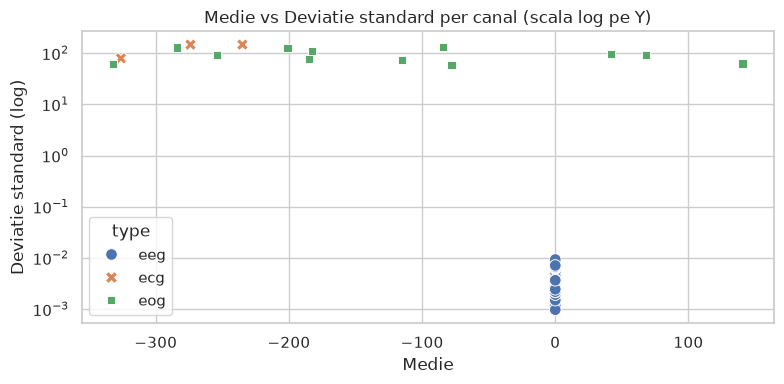

In [19]:
# Scatter plot of channel mean vs std (EEG vs ECG/EOG)

plt.figure(figsize=(8, 4))
sns.scatterplot(data=channel_df, x="mean", y="std", hue="type", style="type", s=70)
plt.yscale("log")
plt.title("Medie vs Deviatie standard per canal (scala log pe Y)")
plt.xlabel("Medie")
plt.ylabel("Deviatie standard (log)")
plt.tight_layout()
plt.savefig(FIG_DIR / "07_mean_vs_std_scatter.png", dpi=150)
plt.show()
plt.close()

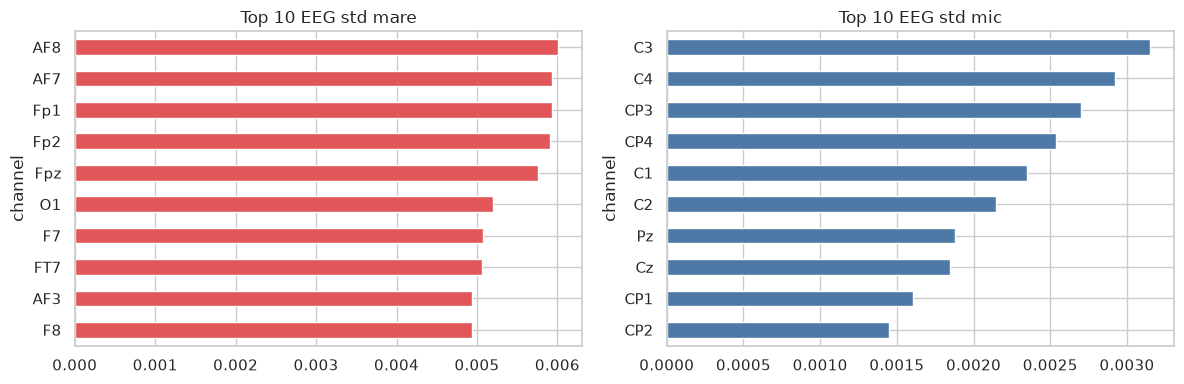

In [20]:
# Horizontal bar charts of Top 10 highest/lowest EEG std and partial flatlines

eeg_avg = eeg_only.groupby("channel")["std"].mean().sort_values()
top10 = eeg_avg.tail(10)
bot10 = eeg_avg.head(10)
  
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
top10.plot(kind="barh", ax=axes[0], color="#E15759", title="Top 10 EEG std mare")
bot10.plot(kind="barh", ax=axes[1], color="#4E79A7", title="Top 10 EEG std mic")
  
plt.tight_layout()
plt.savefig(FIG_DIR / "08_top_bottom_var_channels.png", dpi=150) 
plt.show() 
plt.close() 

In [21]:
# Load one representative subject temporarily for signal plots (4, 9, 10, 11, 12)

rep_sub = subjects[0]
rep_data = np.load(cfg.get_subject_npz_path(rep_sub), allow_pickle=True)
X_rep = rep_data["X"]
y_rep = rep_data["y"].astype(str)
print(f"Incarcat temporar subiect {rep_sub:02d} pentru grafice: shape={X_rep.shape}")

Incarcat temporar subiect 01 pentru grafice: shape=(600, 64, 4001)


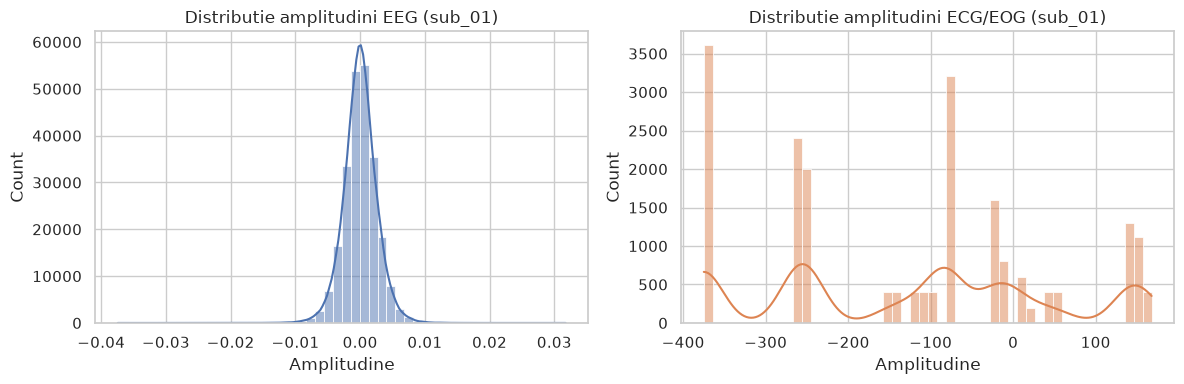

In [22]:
# Histogram + KDE of EEG vs Auxiliary amplitudes (sample trials)

sample_idx = rng.choice(X_rep.shape[0], size=10, replace=False)
eeg_sample_vals = X_rep[sample_idx, :59, ::10].ravel()
aux_sample_vals = X_rep[sample_idx, 59:, ::10].ravel()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(eeg_sample_vals, bins=50, kde=True, ax=axes[0], color="#4C72B0")
axes[0].set_title(f"Distributie amplitudini EEG (sub_{rep_sub:02d})")
axes[0].set_xlabel("Amplitudine")

sns.histplot(aux_sample_vals, bins=50, kde=True, ax=axes[1], color="#DD8452")
axes[1].set_title(f"Distributie amplitudini ECG/EOG (sub_{rep_sub:02d})")
axes[1].set_xlabel("Amplitudine")

plt.tight_layout()
plt.savefig(FIG_DIR / "04_amplitude_hist_kde.png", dpi=150)
plt.show()
plt.close()

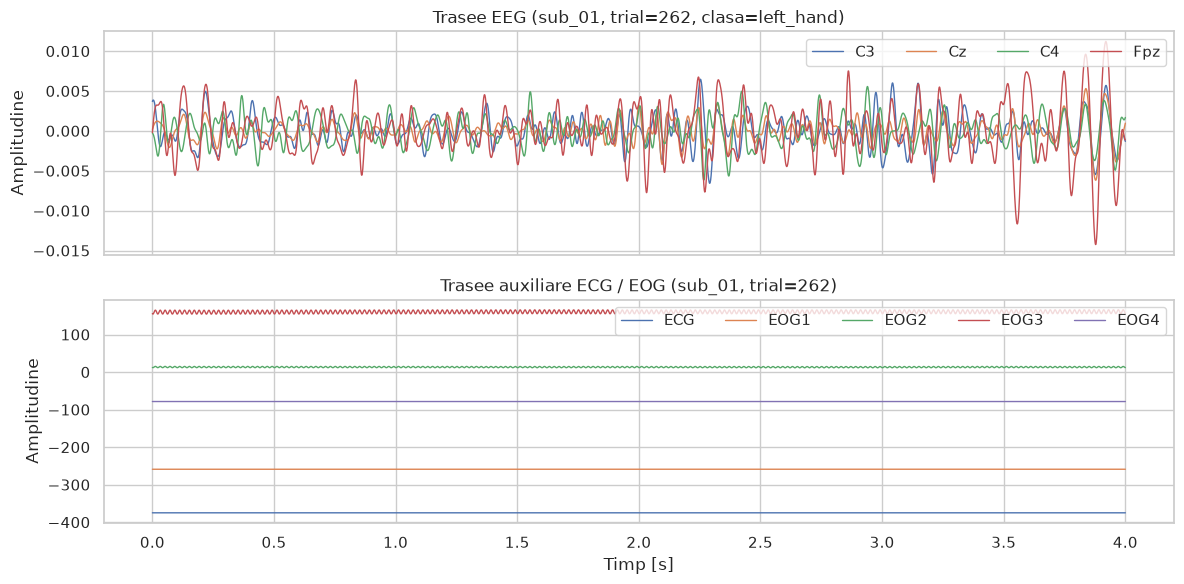

In [23]:
# Line plots of EEG and Aux waveforms for one sample trial

t_idx = int(rng.integers(0, X_rep.shape[0]))
time_sec = np.arange(X_rep.shape[2]) / cfg.EXPECTED_SFREQ_HZ

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
for ch in ["C3", "Cz", "C4", "Fpz"]:
    axes[0].plot(time_sec, X_rep[t_idx, cfg.MED_COLUMNS.index(ch), :], label=ch, linewidth=1.0)
axes[0].set_title(f"Trasee EEG (sub_{rep_sub:02d}, trial={t_idx}, clasa={y_rep[t_idx]})")
axes[0].set_ylabel("Amplitudine")
axes[0].legend(loc="upper right", ncol=4)

for ch in ["ECG", "EOG1", "EOG2", "EOG3", "EOG4"]:
    axes[1].plot(time_sec, X_rep[t_idx, cfg.MED_COLUMNS.index(ch), :], label=ch, linewidth=1.0)
axes[1].set_title(f"Trasee auxiliare ECG / EOG (sub_{rep_sub:02d}, trial={t_idx})")
axes[1].set_xlabel("Timp [s]")
axes[1].set_ylabel("Amplitudine")
axes[1].legend(loc="upper right", ncol=5)

plt.tight_layout()
plt.savefig(FIG_DIR / "09_sample_eeg_and_aux_traces.png", dpi=150)
plt.show()
plt.close()

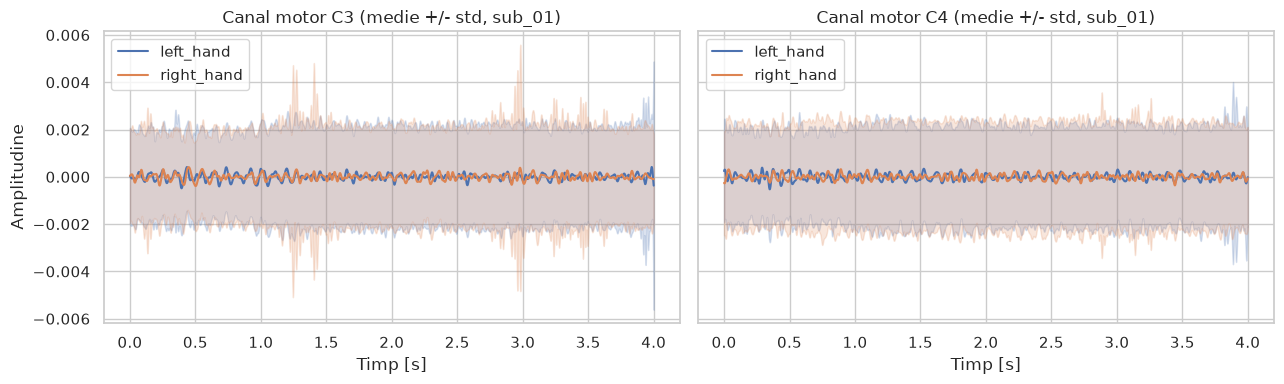

In [24]:
# Mean +/- std shaded line plots on motor channels C3 and C4

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, ch in zip(axes, ["C3", "C4"]):
    ch_i = cfg.MED_COLUMNS.index(ch)
    for lbl, col in [("left_hand", "#4C72B0"), ("right_hand", "#DD8452")]:
        sig = X_rep[y_rep == lbl, ch_i, :]
        m = sig.mean(axis=0)
        s = sig.std(axis=0)
        ax.plot(time_sec, m, label=lbl, color=col)
        ax.fill_between(time_sec, m - s, m + s, color=col, alpha=0.2)
    ax.set_title(f"Canal motor {ch} (medie +/- std, sub_{rep_sub:02d})")
    ax.set_xlabel("Timp [s]")
    ax.legend()
axes[0].set_ylabel("Amplitudine")

plt.tight_layout()
plt.savefig(FIG_DIR / "10_motor_c3_c4_mean_std.png", dpi=150)
plt.show()
plt.close()

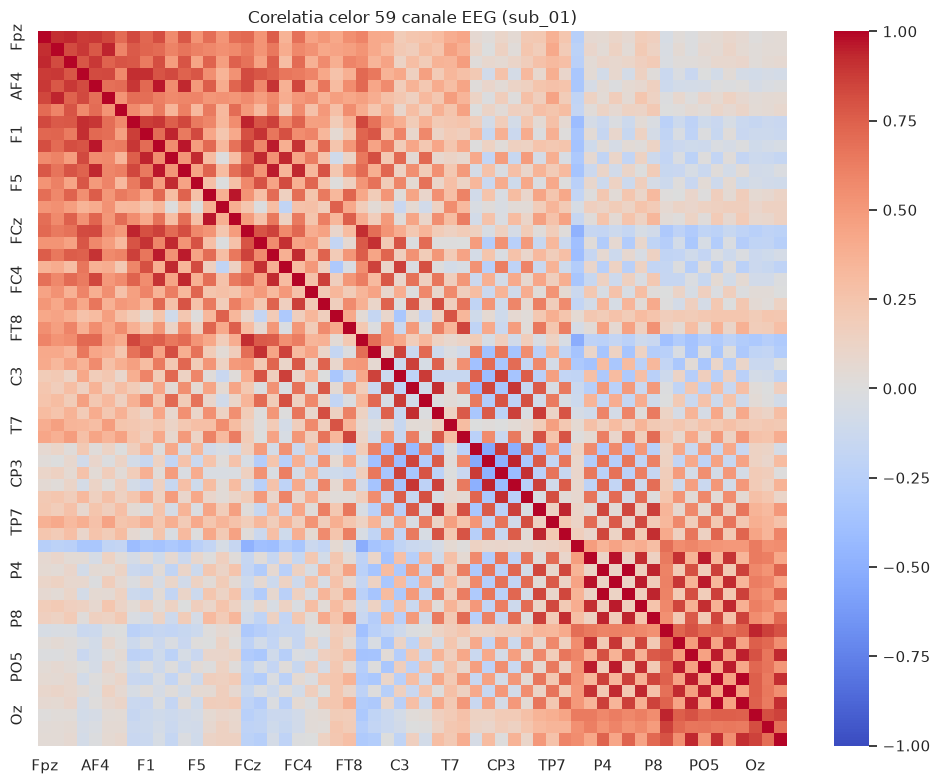

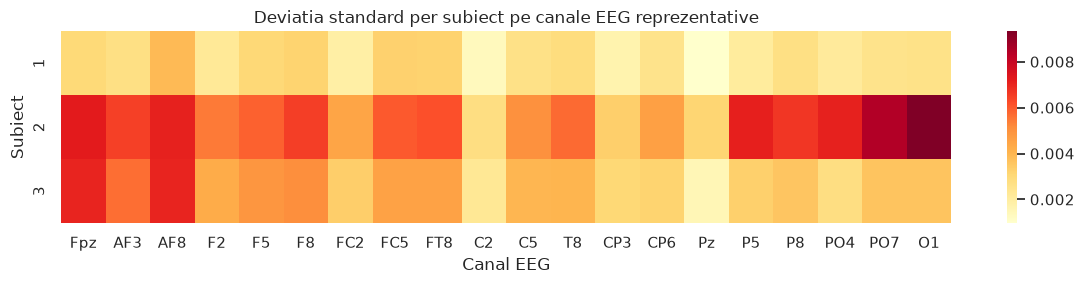

In [25]:
# Heatmaps (EEG channel correlation + std across subjects)

corr_idx = rng.choice(X_rep.shape[0], size=30, replace=False)
eeg_flat = X_rep[corr_idx, :59, :].transpose(1, 0, 2).reshape(59, -1)
corr_df = pd.DataFrame(np.corrcoef(eeg_flat), index=cfg.EEG_CHANNELS, columns=cfg.EEG_CHANNELS)

plt.figure(figsize=(10, 8))
sns.heatmap(corr_df, cmap="coolwarm", center=0, vmin=-1, vmax=1, xticklabels=4, yticklabels=4)
plt.title(f"Corelatia celor 59 canale EEG (sub_{rep_sub:02d})")
plt.tight_layout()
plt.savefig(FIG_DIR / "11a_eeg_correlation_heatmap.png", dpi=150)
plt.show()
plt.close()

std_matrix = eeg_only.pivot(index="subject_id", columns="channel", values="std")[cfg.EEG_CHANNELS[::3]]
plt.figure(figsize=(12, 3))
sns.heatmap(std_matrix, cmap="YlOrRd", annot=False)
plt.title("Deviatia standard per subiect pe canale EEG reprezentative")
plt.xlabel("Canal EEG")
plt.ylabel("Subiect")
plt.tight_layout()
plt.savefig(FIG_DIR / "11b_subject_channel_std_heatmap.png", dpi=150)
plt.show()
plt.close()

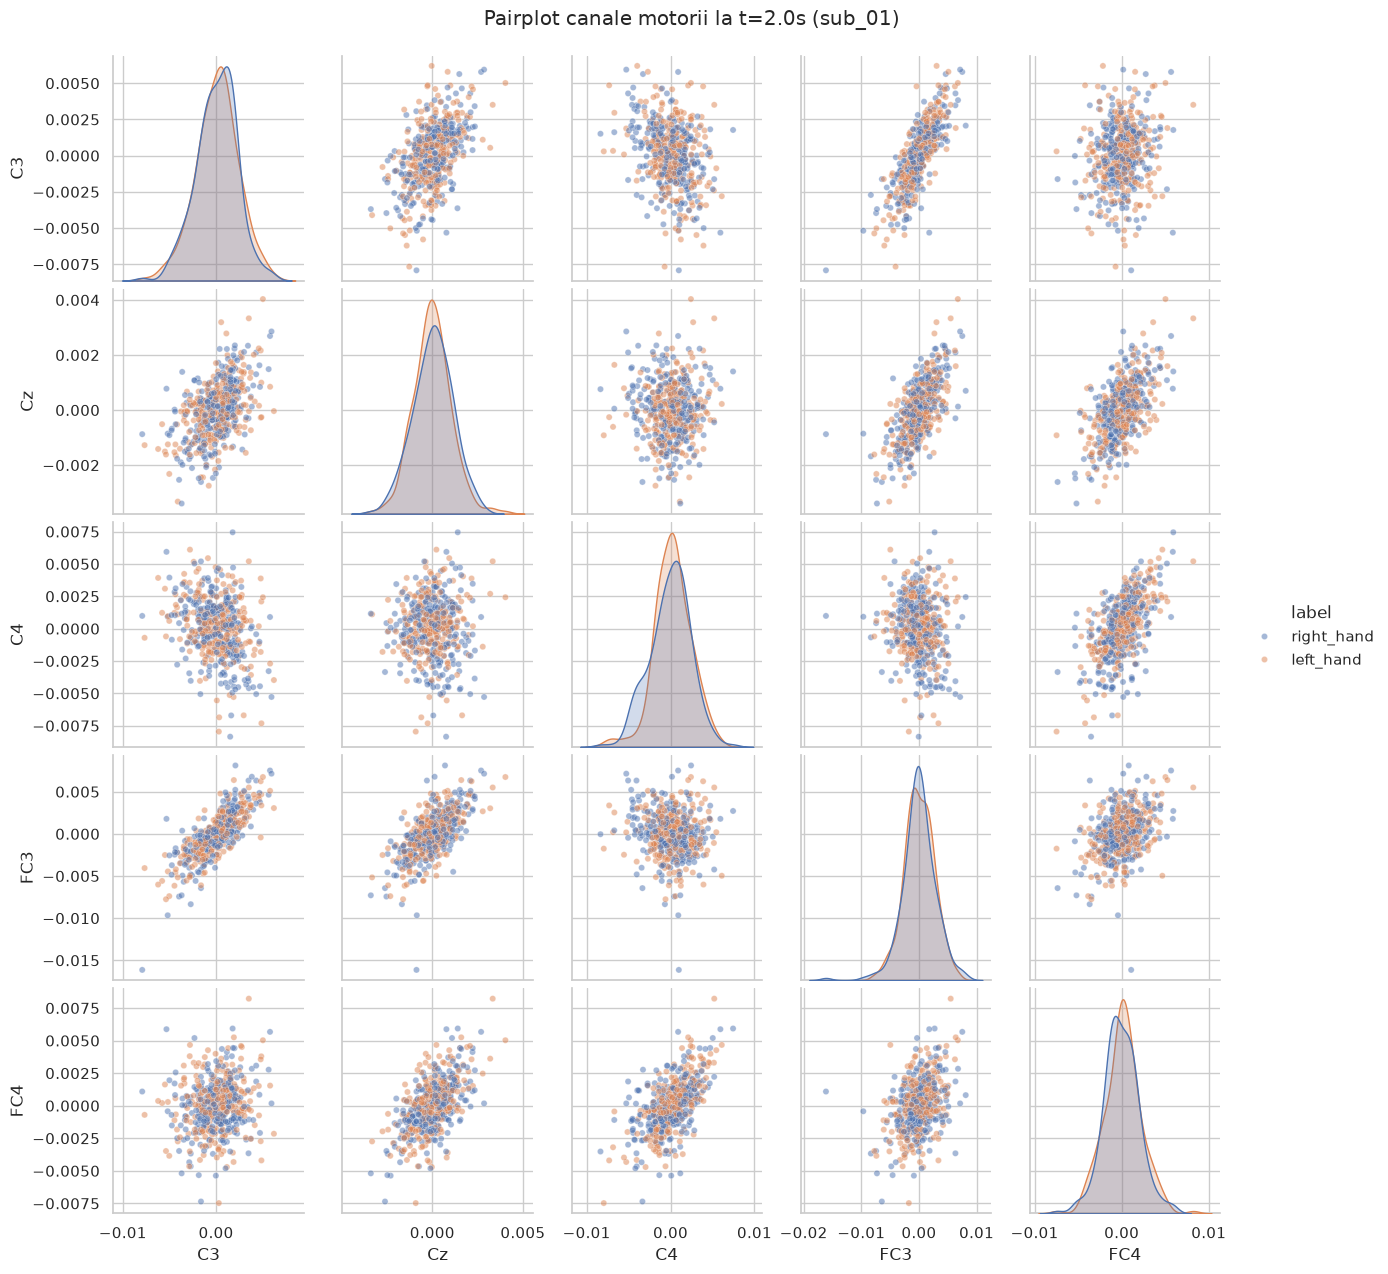

In [26]:
# Pairplot on key motor channels (reproducible 500-point sample)

motor_chs = ["C3", "Cz", "C4", "FC3", "FC4"]
motor_idx = [cfg.MED_COLUMNS.index(ch) for ch in motor_chs]
pair_trials = rng.choice(X_rep.shape[0], size=500, replace=False)
t_mid = X_rep.shape[2] // 2

pair_df = pd.DataFrame(X_rep[pair_trials][:, motor_idx, t_mid], columns=motor_chs)
pair_df["label"] = y_rep[pair_trials]

g = sns.pairplot(pair_df, hue="label", plot_kws={"alpha": 0.5, "s": 20})
g.figure.suptitle(f"Pairplot canale motorii la t=2.0s (sub_{rep_sub:02d})", y=1.02)
g.savefig(FIG_DIR / "12_motor_channels_pairplot.png", dpi=150)
plt.show()
plt.close()

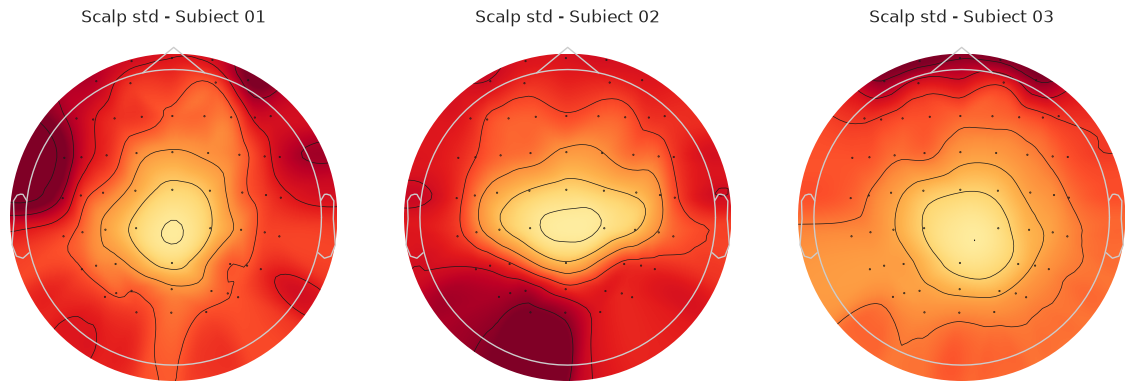

In [27]:
# 2D scalp topomap of EEG channel std across subjects

info = mne.create_info(cfg.EEG_CHANNELS, sfreq=cfg.EXPECTED_SFREQ_HZ, ch_types="eeg")
info.set_montage("standard_1005")

fig, axes = plt.subplots(1, len(subjects), figsize=(4 * len(subjects), 4))
if len(subjects) == 1:
    axes = [axes]

for ax, sub_id in zip(axes, subjects):
    sub_eeg = channel_df[(channel_df["subject_id"] == sub_id) & (channel_df["type"] == "eeg")]
    sub_stds = sub_eeg.set_index("channel").loc[cfg.EEG_CHANNELS, "std"].to_numpy()
    mne.viz.plot_topomap(sub_stds, info, axes=ax, show=False, cmap="YlOrRd")
    ax.set_title(f"Scalp std - Subiect {sub_id:02d}")

plt.tight_layout()
plt.savefig(FIG_DIR / "13_scalp_std_topomap.png", dpi=150)
plt.show()
plt.close()

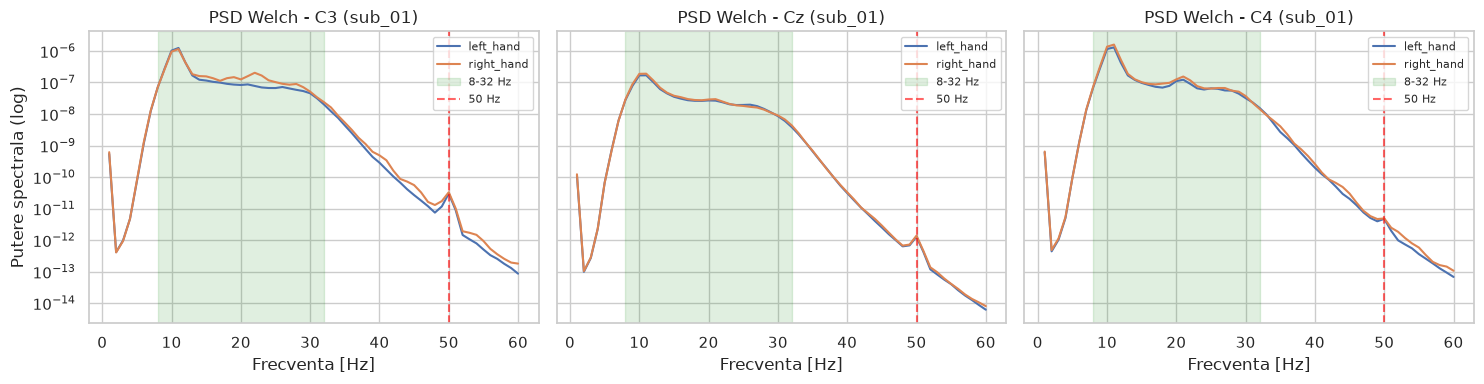

In [28]:
# Welch power spectrum (1-60 Hz) on C3, Cz, C4 to check 8-32 Hz band

from scipy.signal import welch

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, ch in zip(axes, ["C3", "Cz", "C4"]):
    ch_i = cfg.MED_COLUMNS.index(ch)
    for lbl, col in [("left_hand", "#4C72B0"), ("right_hand", "#DD8452")]:
        freqs, psd = welch(X_rep[y_rep == lbl, ch_i, :], fs=cfg.EXPECTED_SFREQ_HZ, nperseg=1000, axis=1)
        mean_psd = psd.mean(axis=0)
        mask = (freqs >= 1) & (freqs <= 60)
        ax.semilogy(freqs[mask], mean_psd[mask], label=lbl, color=col)
    ax.axvspan(cfg.FMIN, cfg.FMAX, color="green", alpha=0.12, label="8-32 Hz")
    ax.axvline(50, color="red", linestyle="--", alpha=0.6, label="50 Hz")
    ax.set_title(f"PSD Welch - {ch} (sub_{rep_sub:02d})")
    ax.set_xlabel("Frecventa [Hz]")
    ax.legend(fontsize=8)
axes[0].set_ylabel("Putere spectrala (log)")

plt.tight_layout()
plt.savefig(FIG_DIR / "14_welch_psd_bandcheck.png", dpi=150)
plt.show()
plt.close()

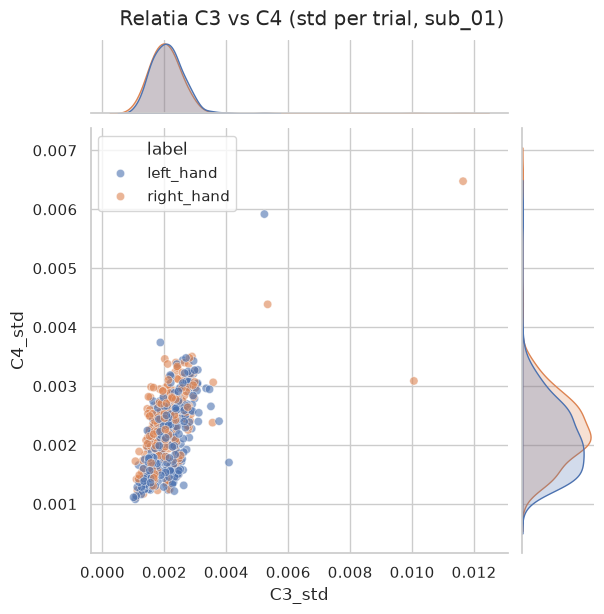

In [29]:
# Jointplot of C3 vs C4 trial-level std by class

c3_std = X_rep[:, cfg.MED_COLUMNS.index("C3"), :].std(axis=1)
c4_std = X_rep[:, cfg.MED_COLUMNS.index("C4"), :].std(axis=1)
joint_df = pd.DataFrame({"C3_std": c3_std, "C4_std": c4_std, "label": y_rep})

g = sns.jointplot(data=joint_df, x="C3_std", y="C4_std", hue="label", alpha=0.6, height=6)
g.figure.suptitle(f"Relatia C3 vs C4 (std per trial, sub_{rep_sub:02d})", y=1.02)
g.savefig(FIG_DIR / "15_c3_vs_c4_jointplot.png", dpi=150)
plt.show()
plt.close()

In [39]:
# Heatmap of flatline trial percentage per subject, session, and flagged channel

check_chs = sorted(flagged_df["channel"].unique().tolist())
if len(check_chs) > 0:
    heat_rows = []
    for sub_id in subjects:
        d = np.load(cfg.get_subject_npz_path(sub_id), allow_pickle=True)
        X_tmp = d["X"]
        sessions_tmp = np.array([str(r[1]) for r in d["metadata"]])
        for ses in sorted(set(sessions_tmp)):
            ses_mask = sessions_tmp == ses
            row = {"sub_ses": f"S{sub_id:02d}-ses{ses}"}
            for ch in check_chs:
                ch_i = cfg.MED_COLUMNS.index(ch)
                row[ch] = 100.0 * (X_tmp[ses_mask, ch_i, :].std(axis=1) <= FLATLINE_THRESHOLD).mean()
            heat_rows.append(row)
        del d, X_tmp
        gc.collect()

    heat_df = pd.DataFrame(heat_rows).set_index("sub_ses")
    plt.figure(figsize=(8, 5))
    sns.heatmap(heat_df, annot=True, fmt=".0f", cmap="Reds", vmin=0, vmax=100)
    plt.title("Procent trialuri flatline (%) pe sesiune si canal semnalat")
    plt.xlabel("Canal")
    plt.ylabel("Subiect - Sesiune")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "16_flatline_by_session_heatmap.png", dpi=150)
    plt.show()
    plt.close()

NameError: name 'flagged_df' is not defined

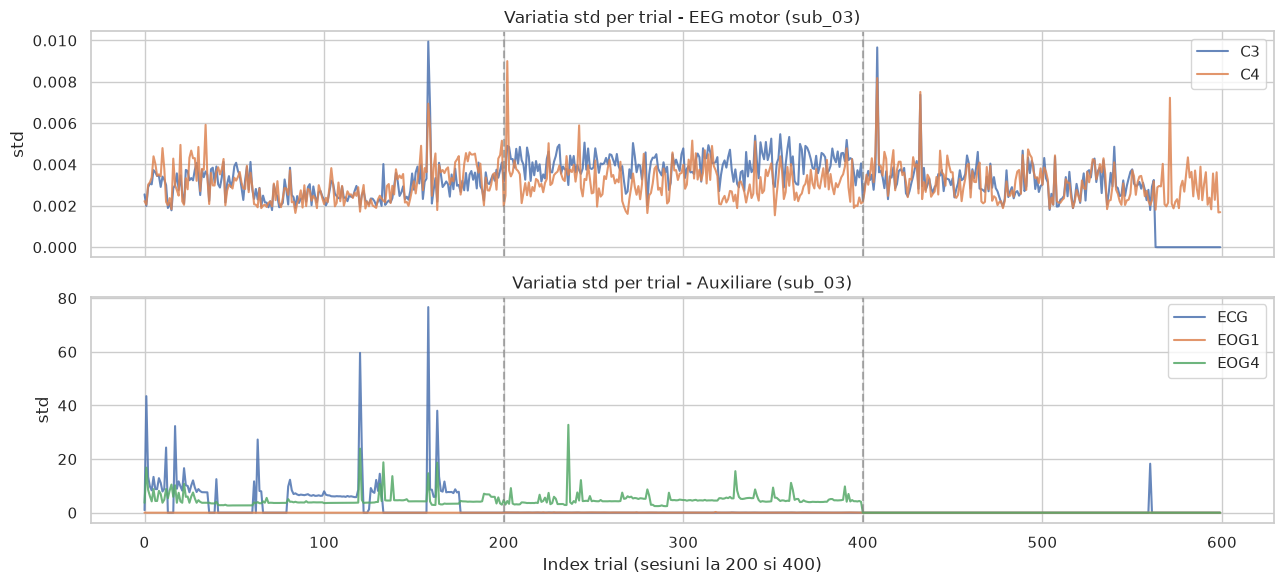

In [40]:
# Trial-by-trial std timeline for Subject 03 (C3 and ECG/EOG dropouts)

sub_check = 3 if 3 in subjects else subjects[-1]
d3 = np.load(cfg.get_subject_npz_path(sub_check), allow_pickle=True)
X_s3 = d3["X"]

fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
for ch in ["C3", "C4"]:
    axes[0].plot(X_s3[:, cfg.MED_COLUMNS.index(ch), :].std(axis=1), label=ch, alpha=0.85)
axes[0].set_title(f"Variatia std per trial - EEG motor (sub_{sub_check:02d})")
axes[0].set_ylabel("std")
axes[0].legend()

for ch in ["ECG", "EOG1", "EOG4"]:
    axes[1].plot(X_s3[:, cfg.MED_COLUMNS.index(ch), :].std(axis=1), label=ch, alpha=0.85)
axes[1].set_title(f"Variatia std per trial - Auxiliare (sub_{sub_check:02d})")
axes[1].set_xlabel("Index trial (sesiuni la 200 si 400)")
axes[1].set_ylabel("std")
axes[1].legend()

for ax in axes:
    ax.axvline(200, color="gray", linestyle="--", alpha=0.6)
    ax.axvline(400, color="gray", linestyle="--", alpha=0.6)

plt.tight_layout()
plt.savefig(FIG_DIR / f"17_trial_std_timeline_sub{sub_check:02d}.png", dpi=150)
plt.show()
plt.close()

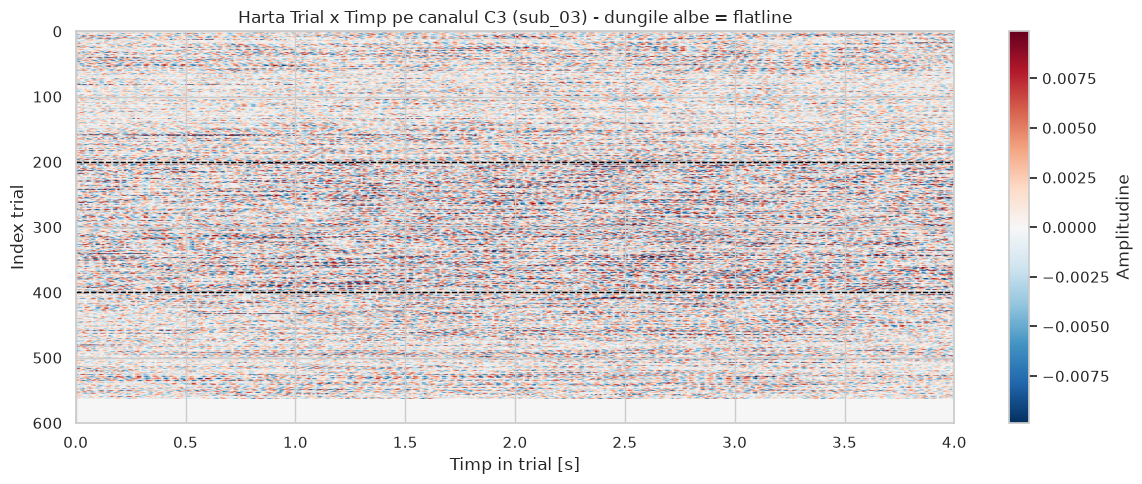

11366

In [41]:
# Trial x Time carpet heatmap for C3 on Subject 03 (flatlines stand out clearly)

c3_mat = X_s3[:, cfg.MED_COLUMNS.index("C3"), ::10]
vmax = float(np.percentile(np.abs(c3_mat), 99))

plt.figure(figsize=(12, 5))
plt.imshow(c3_mat, aspect="auto", cmap="RdBu_r", vmin=-vmax, vmax=vmax, extent=[0, 4.0, len(c3_mat), 0])
plt.colorbar(label="Amplitudine")
plt.axhline(200, color="black", linestyle="--", linewidth=1)
plt.axhline(400, color="black", linestyle="--", linewidth=1)
plt.title(f"Harta Trial x Timp pe canalul C3 (sub_{sub_check:02d}) - dungile albe = flatline")
plt.xlabel("Timp in trial [s]")
plt.ylabel("Index trial")
plt.tight_layout()
plt.savefig(FIG_DIR / f"18_c3_trial_carpet_sub{sub_check:02d}.png", dpi=150)
plt.show()
plt.close()

del d3, X_s3, c3_mat
gc.collect()

In [ ]:
# ECDF of EEG channel std and Top 15 channels by outlier spike ratio

eeg_spike = eeg_only.copy()
eeg_spike["spike_ratio"] = eeg_spike["range"] / (eeg_spike["p95"] - eeg_spike["p05"])
top_spikes = eeg_spike.groupby("channel")["spike_ratio"].max().sort_values().tail(15)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.ecdfplot(data=eeg_spike, x="std", hue="subject_id", ax=axes[0], linewidth=2)
axes[0].set_title("ECDF pentru std pe canalele EEG")
axes[0].set_xlabel("Deviatie standard")
axes[0].set_ylabel("Proportie cumulativa")

top_spikes.plot(kind="barh", ax=axes[1], color="#B07AA1")
axes[1].set_title("Top 15 canale EEG dupa raportul de spike (range / IQR90)")
axes[1].set_xlabel("range / (p95 - p05)")

plt.tight_layout()
plt.savefig(FIG_DIR / "19_eeg_outlier_ecdf.png", dpi=150)
plt.show()
plt.close()

In [43]:
# Free temporary subject arrays from memory

del rep_data, X_rep, y_rep, eeg_flat, corr_df, pair_df
gc.collect()
print("Memoria a fost eliberata.")

Memoria a fost eliberata.
